# Weighted Edge Degree & Jaccard Index Analysis
This notebook implements the weighted edge degree approach. For an unthresholded absolute correlation matrix $W$, the weighted edge degree for an edge between node $i$ and node $j$ is defined as:
$$ED_{ij} = s_i + s_j - 2W_{ij}$$
where $s_i$ is the node strength (sum of incident weights) of node $i$.

In [16]:
import os
import pandas as pd
import numpy as np
from tqdm import tqdm

base_dir = '/home/aloo/CNS_Summer_Project_1/correlation_matrices_segment_wise_(notAbsolute)'

# 1. Identify subjects with multiple sessions
subjects_with_multiple_sessions = []
for subject in os.listdir(base_dir):
    if subject.startswith('sub-'):
        subject_path = os.path.join(base_dir, subject)
        if os.path.isdir(subject_path):
            sessions = [d for d in os.listdir(subject_path) if d.startswith('ses-')]
            if len(sessions) > 1:
                subjects_with_multiple_sessions.append(subject)

# 2. Exclude specific subjects if necessary (sub-NORB00074 is excluded in other analyses)
excluded_subjects = ['sub-NORB00074']
filtered_subjects = sorted([sub for sub in subjects_with_multiple_sessions if sub not in excluded_subjects])
print(f"Found {len(filtered_subjects)} subjects with multiple sessions.")

# 3. Load the data
segment_matrices = {}

for subject in tqdm(filtered_subjects, desc="Loading subjects"):
    subject_path = os.path.join(base_dir, subject)
    segment_matrices[subject] = {}
    
    for session in os.listdir(subject_path):
        if not session.startswith('ses-'):
            continue
            
        ses_path = os.path.join(subject_path, session)
        if os.path.isdir(ses_path):
            segment_matrices[subject][session] = {}
            for file in os.listdir(ses_path):
                if file.endswith('.csv'):
                    # Extract segment name
                    parts = file.split('_')
                    segment = next((p for p in parts if p.startswith('segment-')), None)
                    
                    if segment:
                        file_path = os.path.join(ses_path, file)
                        df = pd.read_csv(file_path, index_col=0)
                        segment_matrices[subject][session][segment] = df

print(f"Successfully loaded correlation matrices for {len(segment_matrices)} subjects.")

Found 20 subjects with multiple sessions.


Loading subjects: 100%|██████████| 20/20 [00:01<00:00, 18.66it/s]

Successfully loaded correlation matrices for 20 subjects.


In [17]:
# 4. Compute Weighted Edge Degrees
edge_degree_matrices = {}

for subject, sessions in tqdm(segment_matrices.items(), desc="Computing edge degrees"):
    edge_degree_matrices[subject] = {}
    
    for session, segments in sessions.items():
        edge_degree_matrices[subject][session] = {}
        
        for segment, df in segments.items():
            # Take modulus (absolute value) of the correlation matrix
            W = df.abs().values
            
            # Set diagonal to 0 to ignore self-correlation in strength calculations
            np.fill_diagonal(W, 0)
            
            # Calculate node strength s_i for each node
            s = np.sum(W, axis=1)
            
            n = len(s)
            ED = np.zeros((n, n))
            
            # Calculate weighted edge degree for each pair (i, j)
            # ED_ij = s_i + s_j - 2 * W_ij
            for i in range(n):
                for j in range(n):
                    if i != j:
                        ED[i, j] = s[i] + s[j] - 2 * W[i, j]
            
            # Store it as a dataframe with same index/columns as original
            edge_degree_df = pd.DataFrame(ED, index=df.index, columns=df.columns)
            edge_degree_matrices[subject][session][segment] = edge_degree_df

print("Successfully calculated weighted edge degrees for all segments.")

Computing edge degrees: 100%|██████████| 20/20 [00:00<00:00, 77.05it/s]

Successfully calculated weighted edge degrees for all segments.


Plotting edge degree heatmaps for subject: sub-NORB00064

--- ses-3 (17 segments) ---


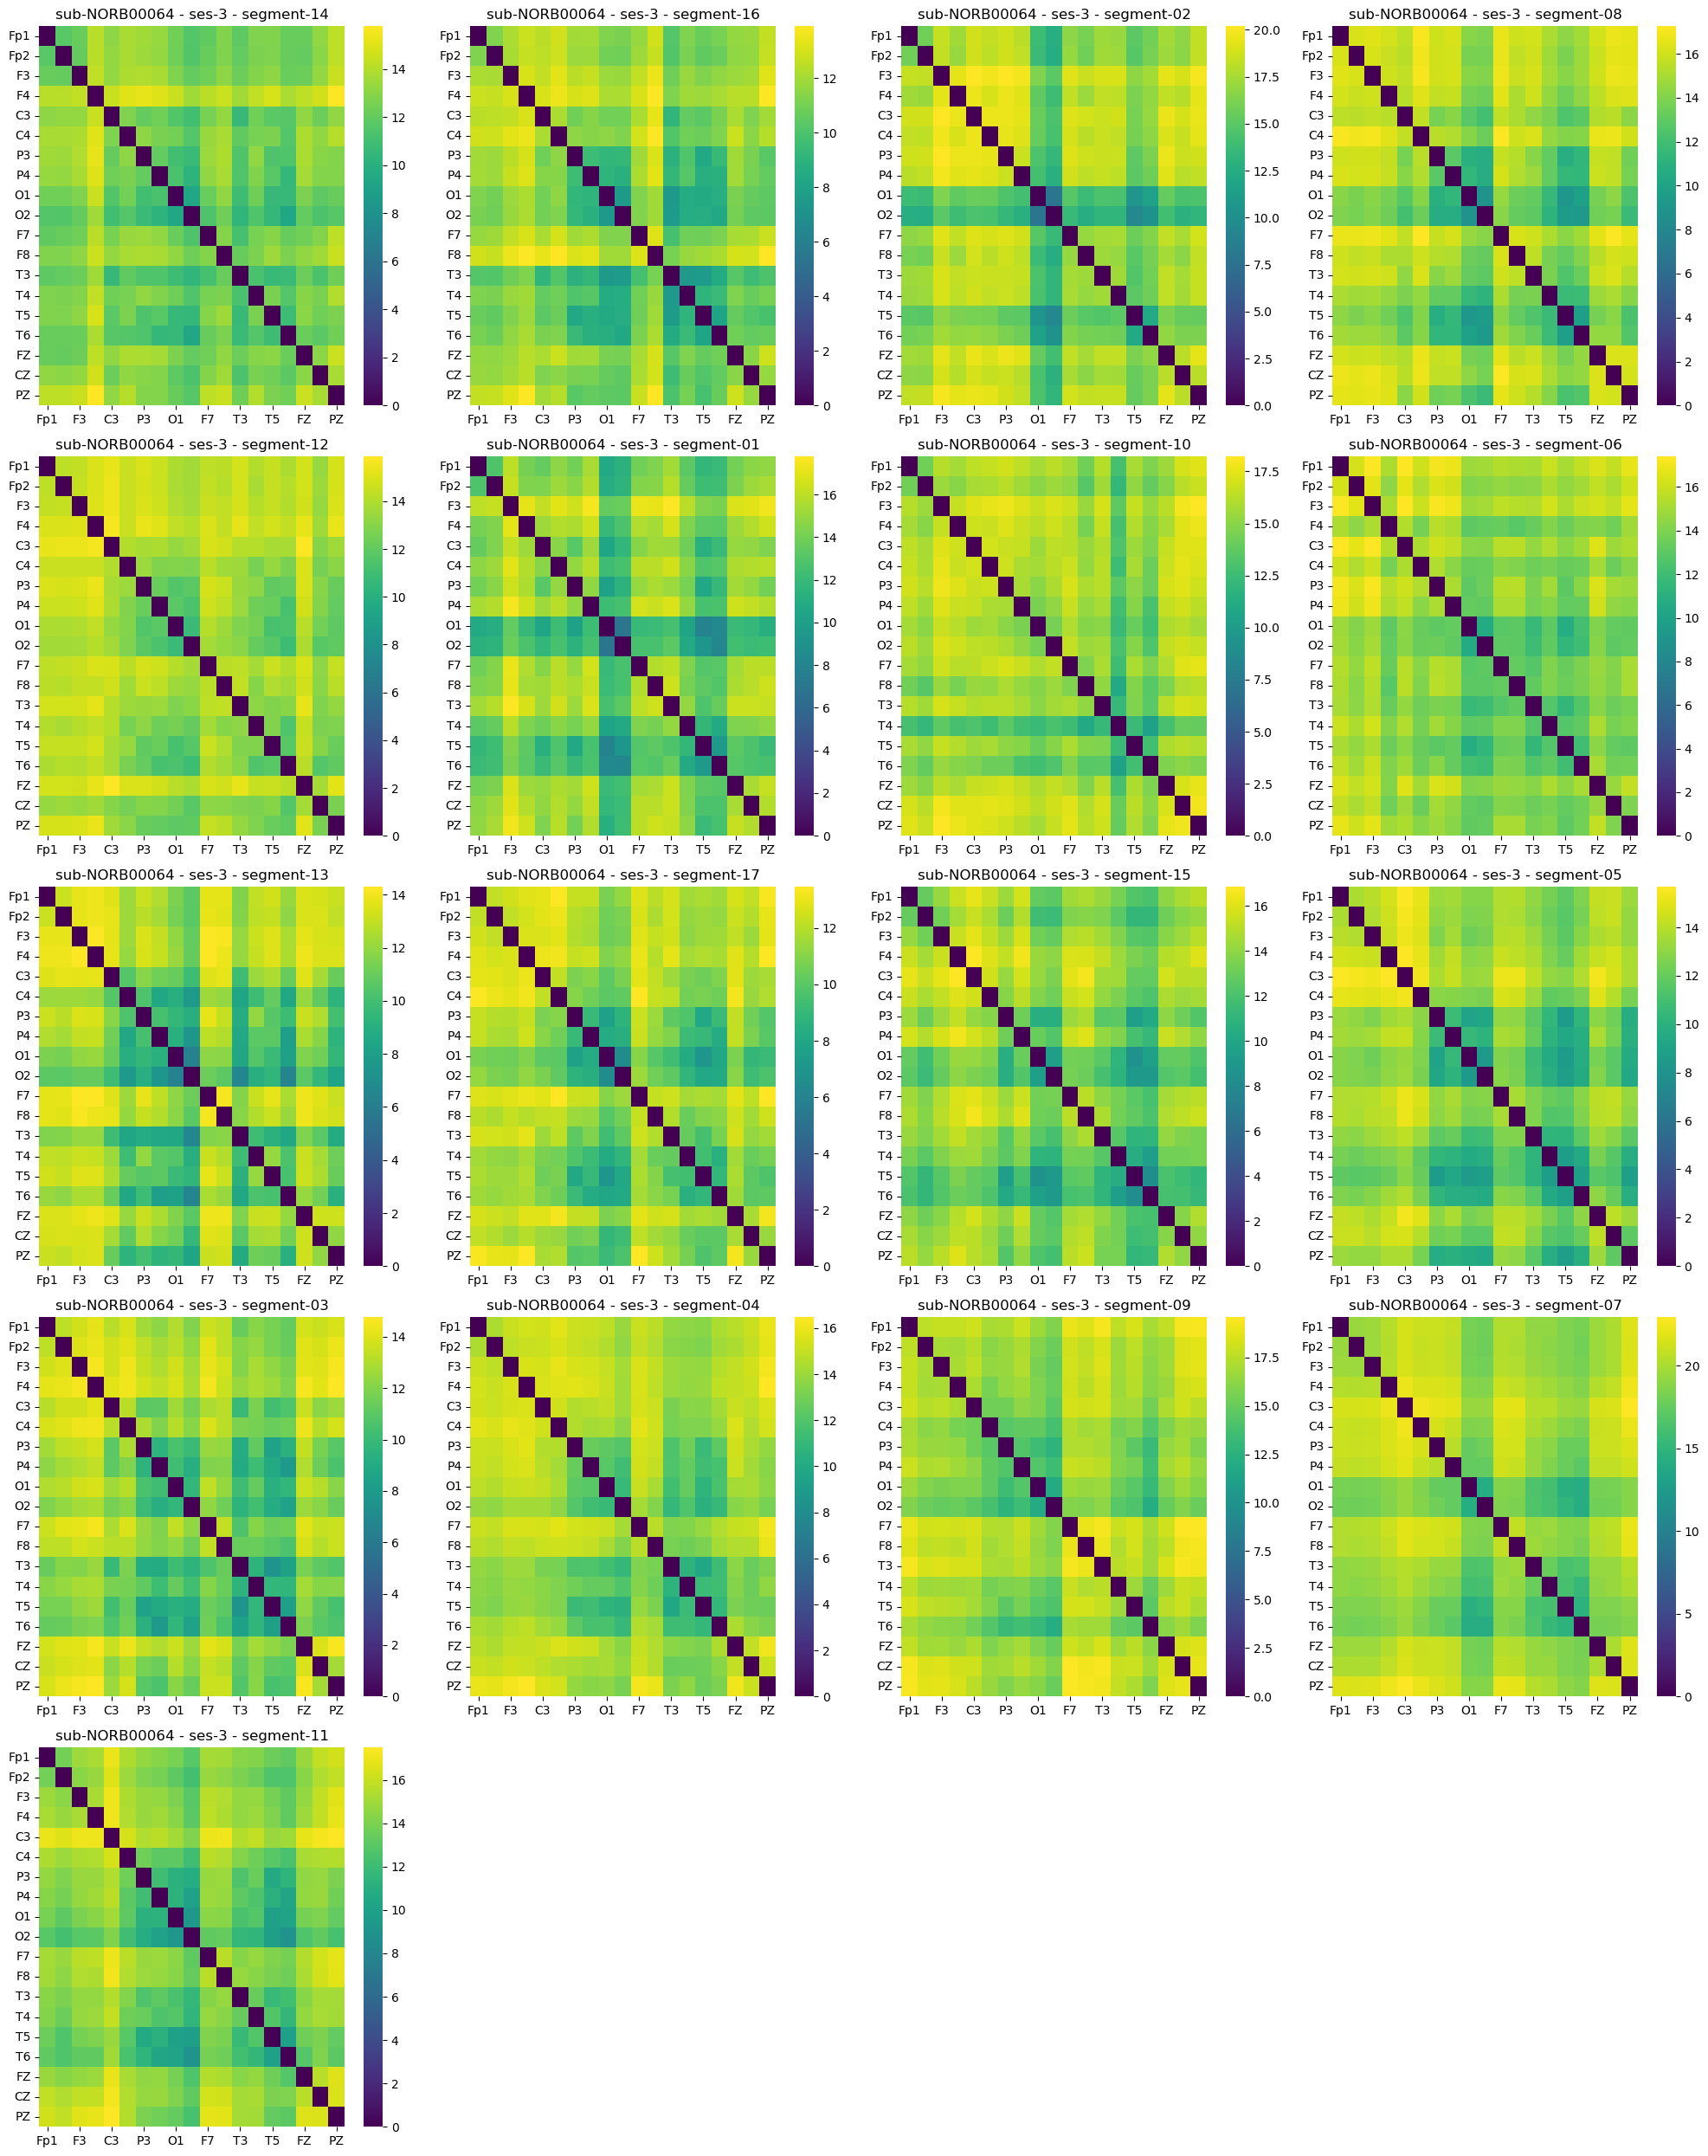


--- ses-2 (20 segments) ---


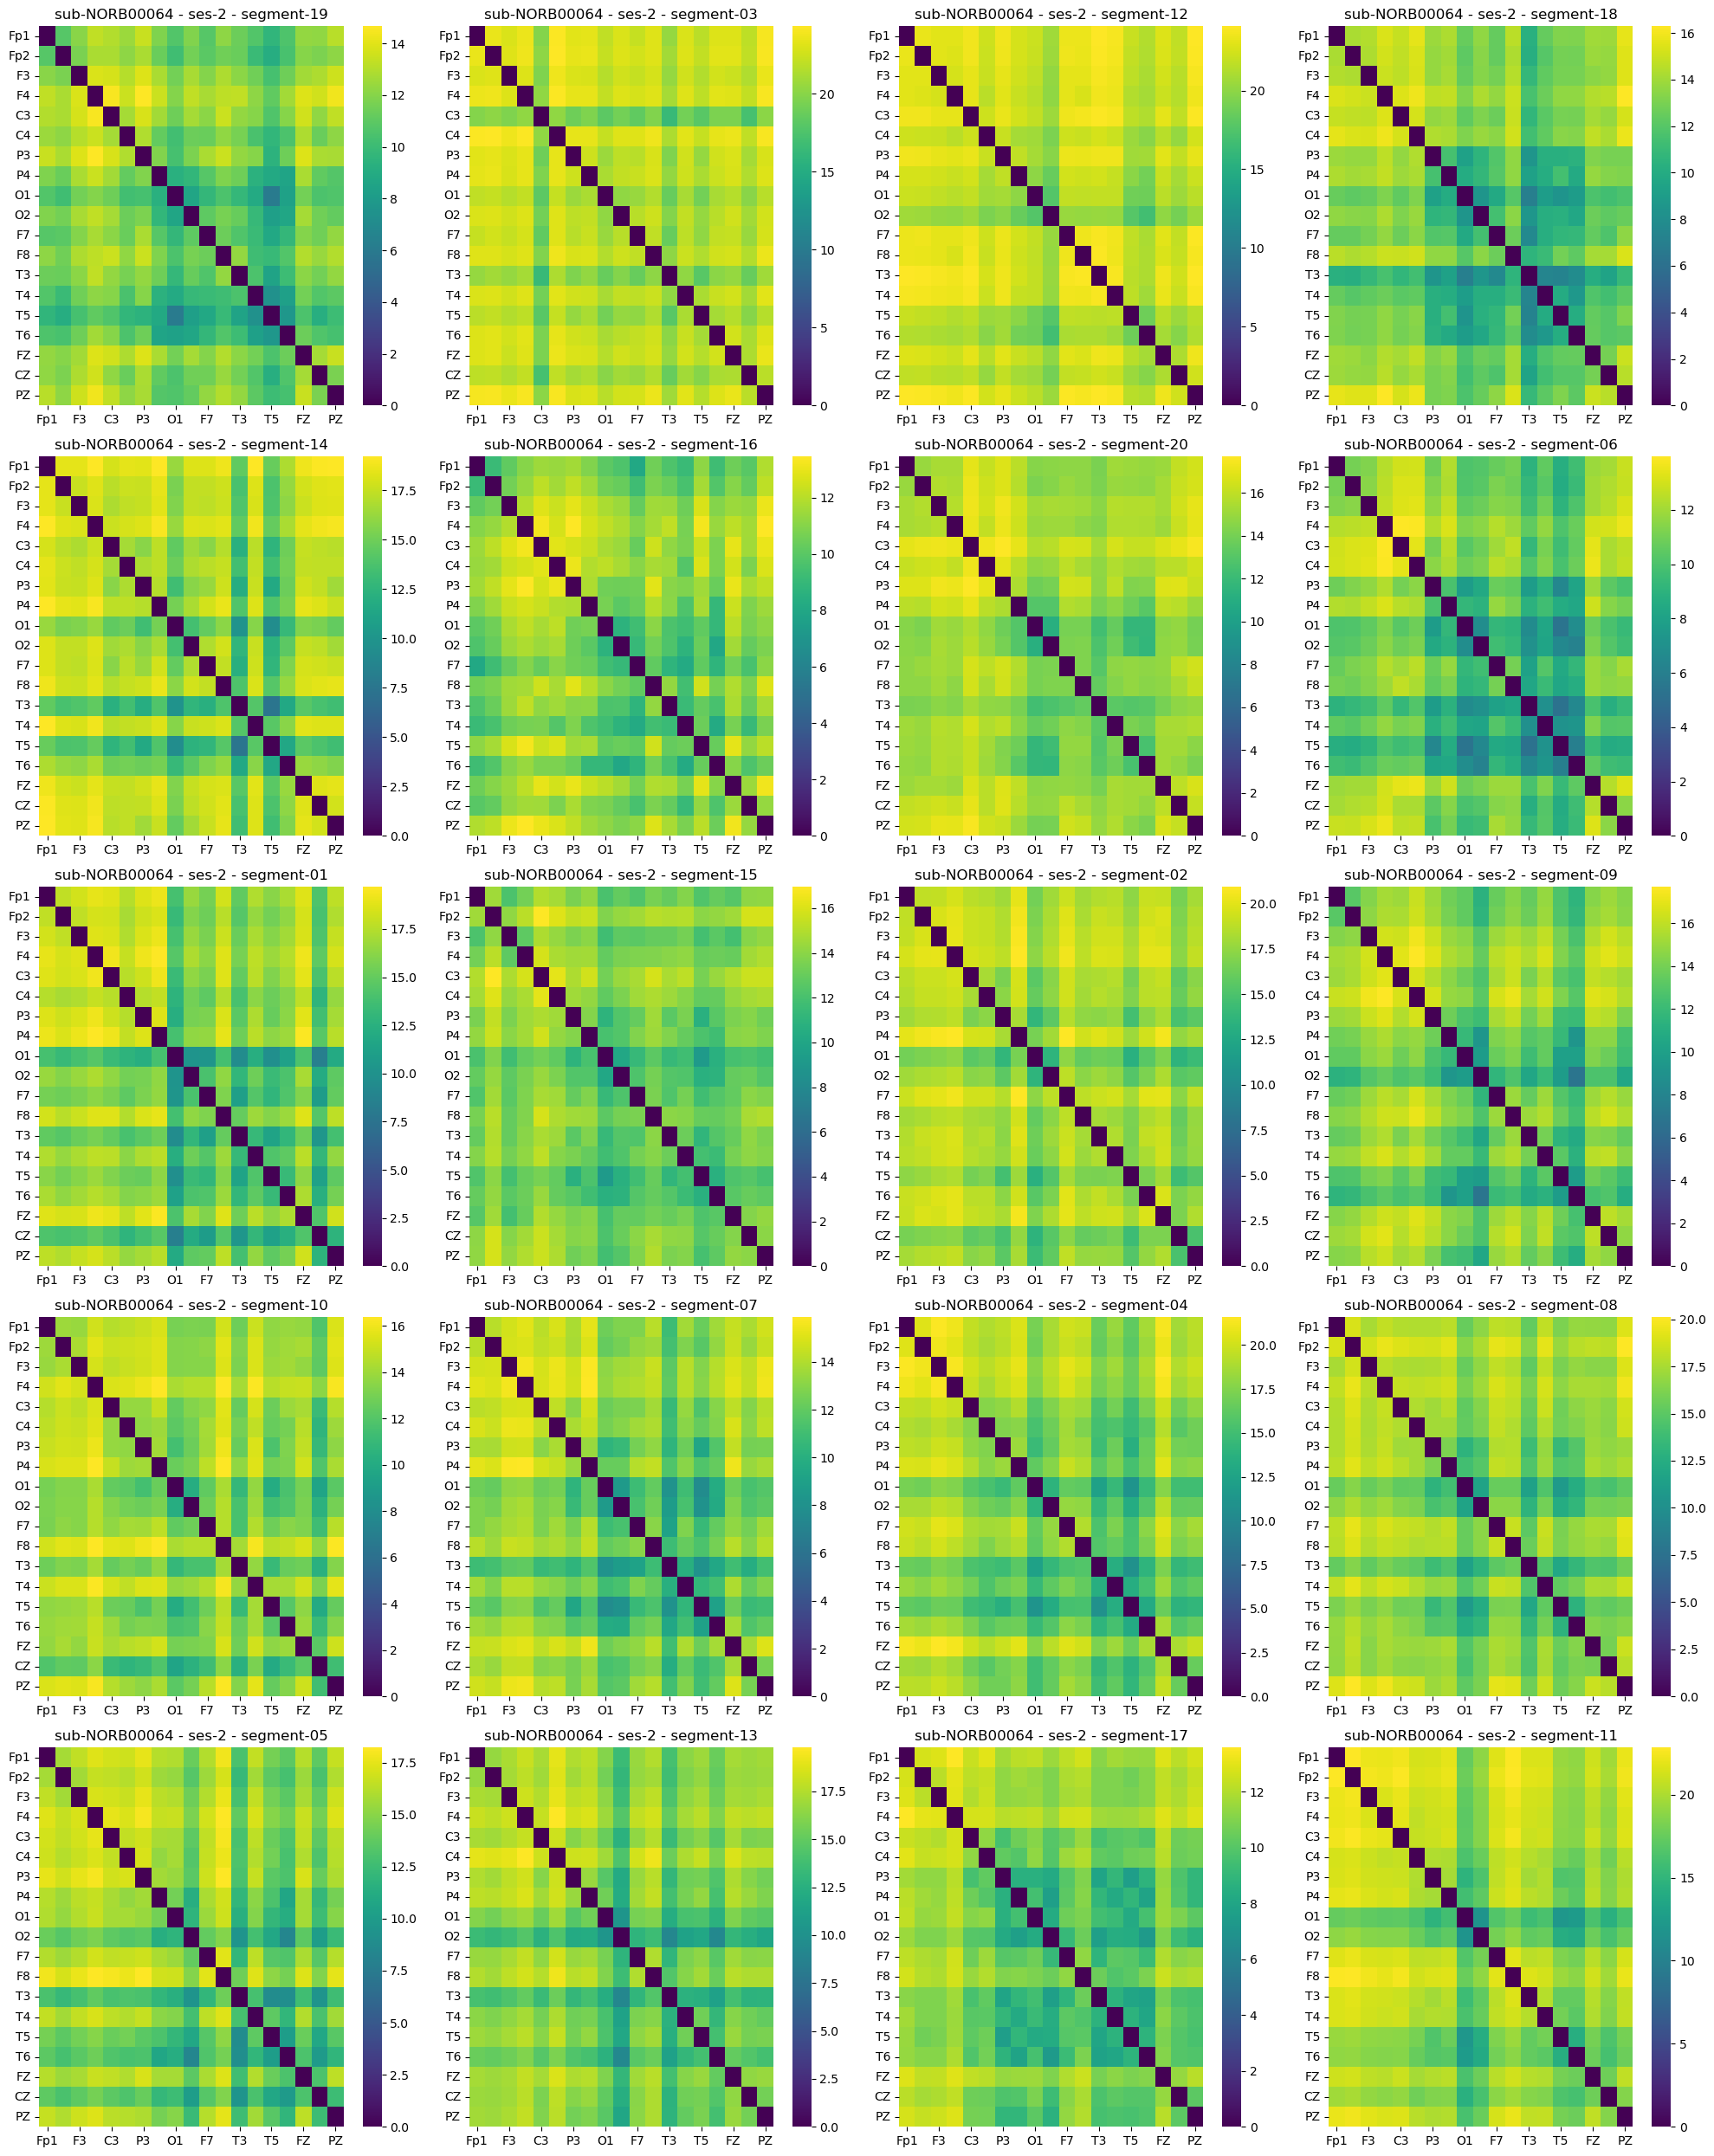


--- ses-1 (13 segments) ---


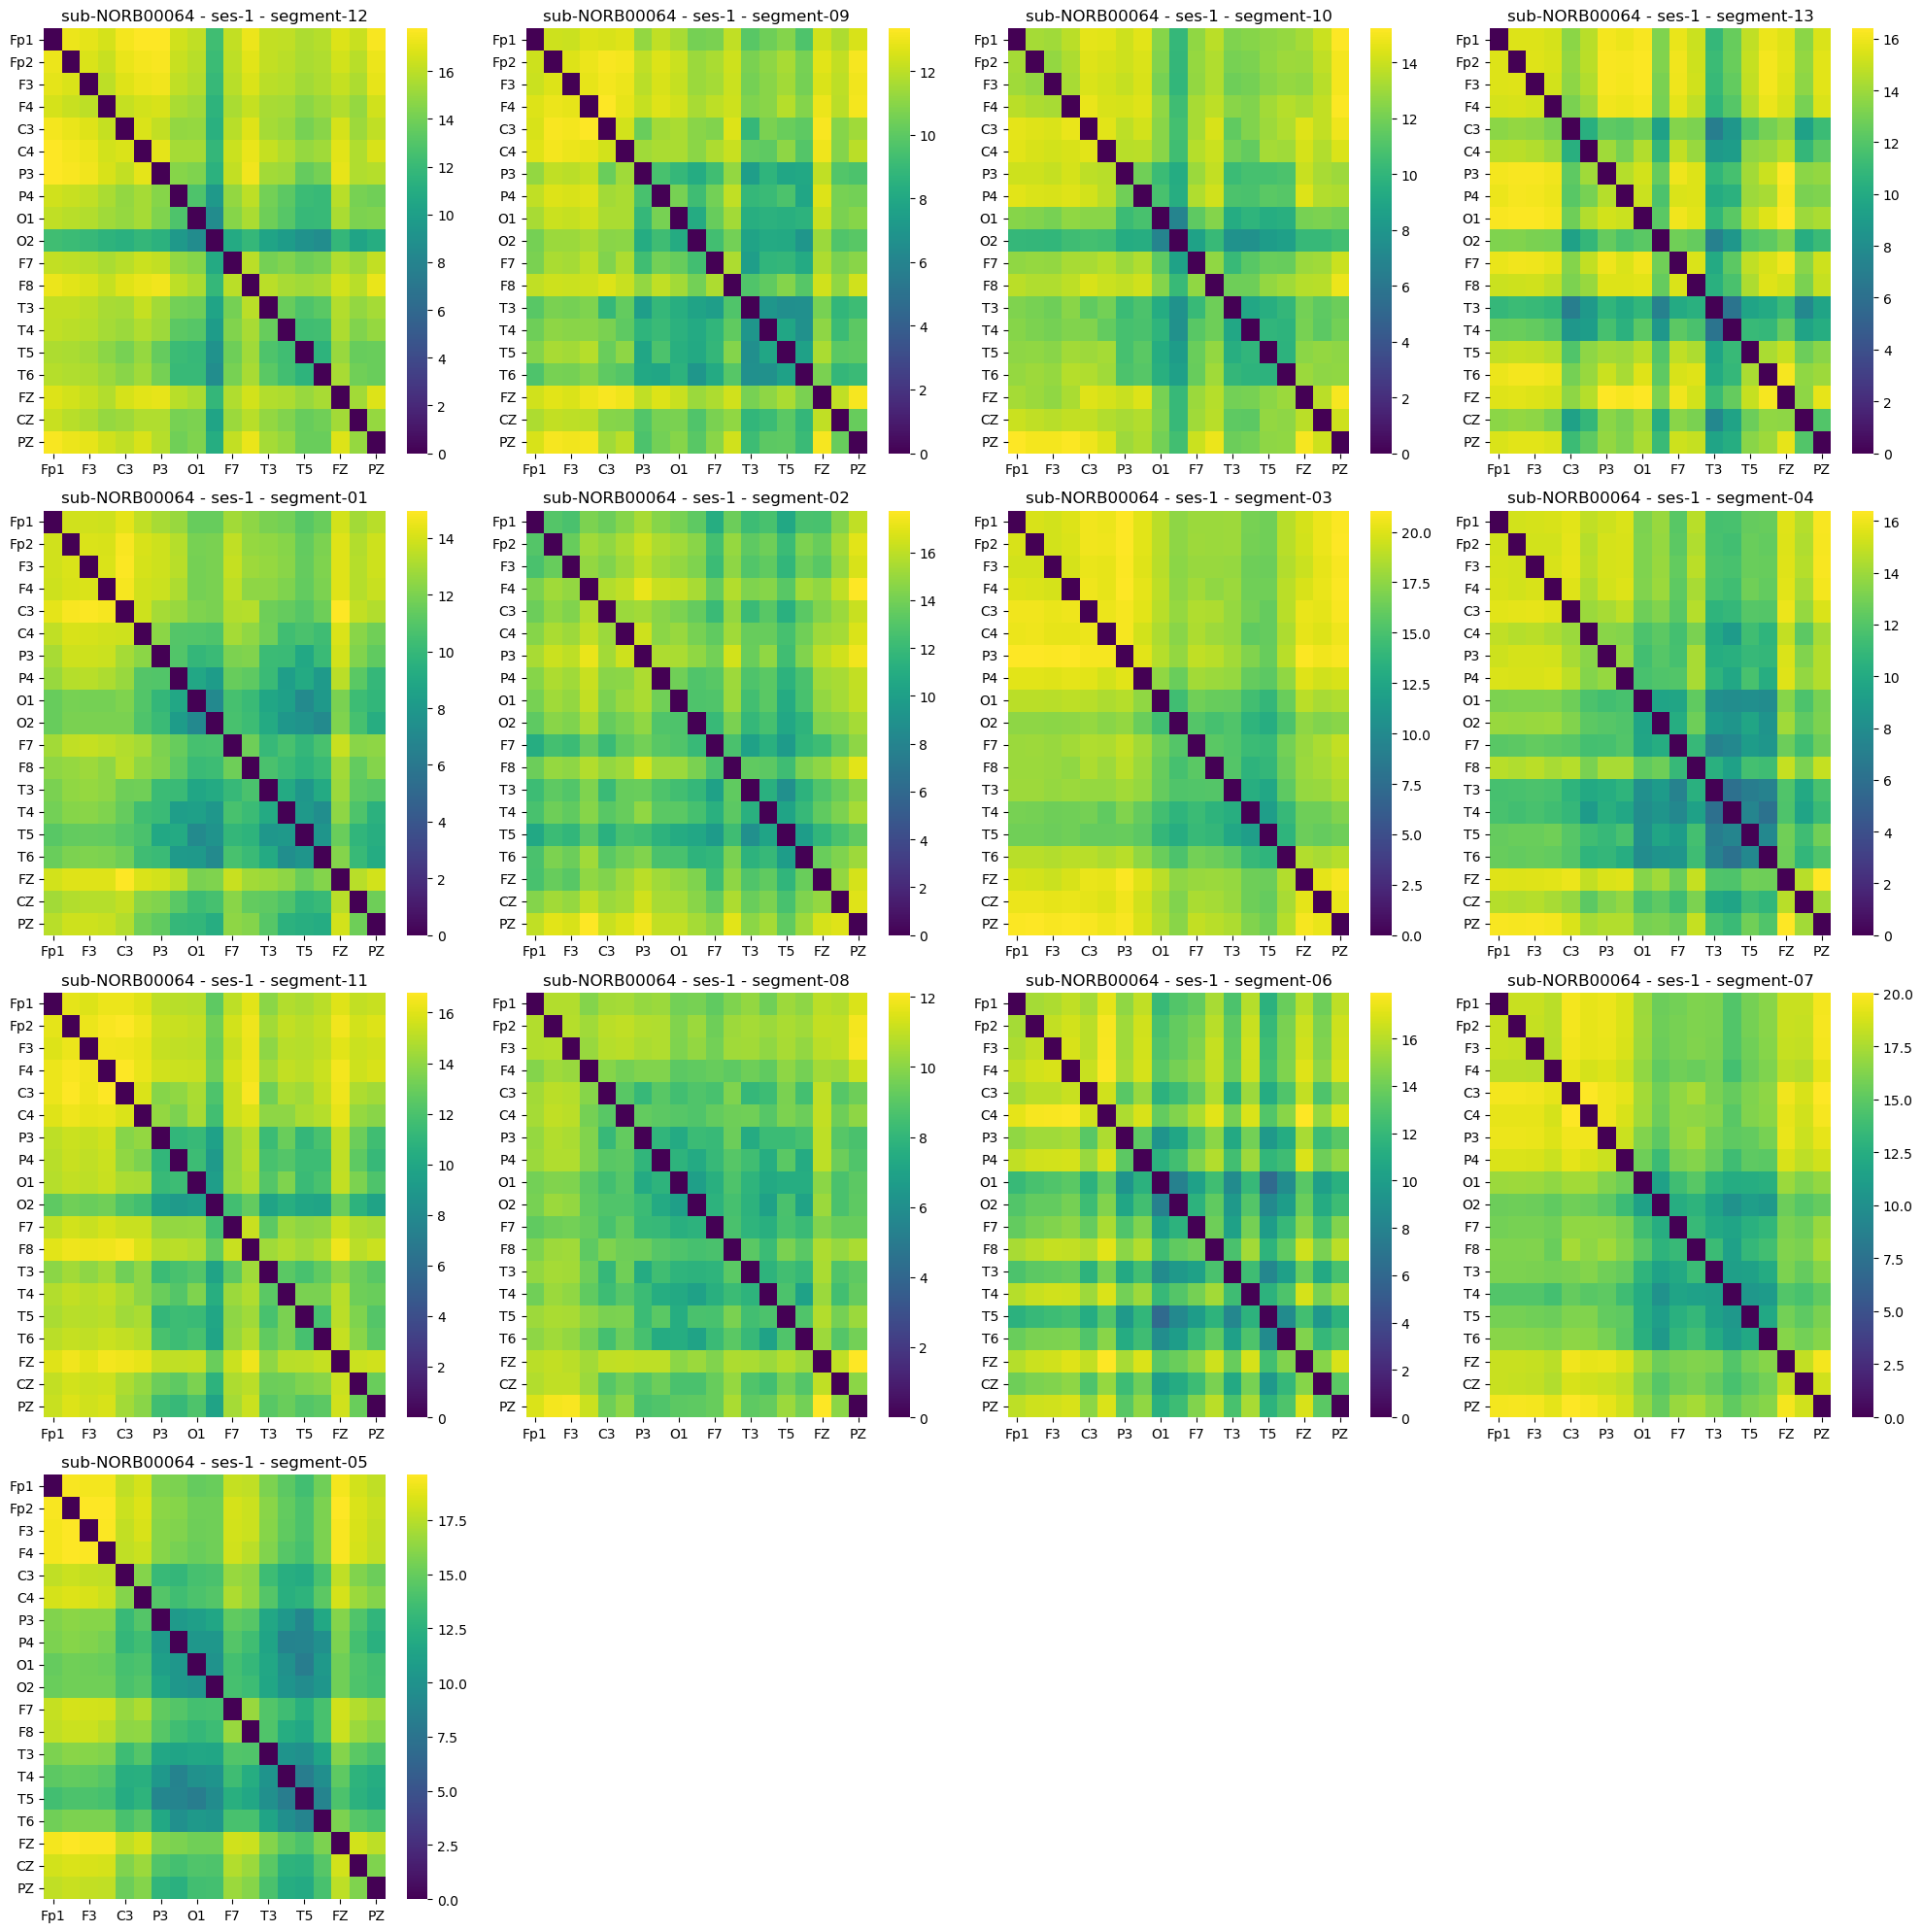

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# 5. Plot Heatmaps for a Single Subject across all segments
# Pick the first subject
subject = filtered_subjects[0]
print(f"Plotting edge degree heatmaps for subject: {subject}")

# Get all sessions for this subject
sessions = list(edge_degree_matrices[subject].keys())

for session in sessions:
    segments = edge_degree_matrices[subject][session]
    num_segments = len(segments)
    if num_segments == 0:
        continue
        
    print(f"\n--- {session} ({num_segments} segments) ---")
    
    # Set up a matplotlib grid for the heatmaps
    cols = 4
    rows = (num_segments + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(20, 5 * rows))
    
    # Ensure axes is a flat array
    if isinstance(axes, np.ndarray):
        axes = axes.flatten()
    else:
        axes = [axes]
    
    for idx, (segment, df) in enumerate(segments.items()):
        ax = axes[idx]
        sns.heatmap(df, cmap='viridis', ax=ax, cbar=True)
        ax.set_title(f"{subject} - {session} - {segment}")
        
    # Hide any unused subplots
    for idx in range(num_segments, len(axes)):
        fig.delaxes(axes[idx])
        
    plt.tight_layout()
    plt.show()

In [19]:
from itertools import combinations
from IPython.display import display

# 6. Calculate Edge-wise Jaccard Index across segments of ses-1 between different subjects
# Load ages
age_df = pd.read_csv('/home/aloo/CNS_Summer_Project_1/age_acq_time_sorted.csv')
age_dict = dict(zip(age_df['label'], age_df['age_acq_time']))

jaccard_rows = []

# We will look at 'ses-1'
target_session = 'ses-1'

# Get all subjects that have 'ses-1'
subjects_with_ses1 = [sub for sub in filtered_subjects if target_session in edge_degree_matrices[sub]]
print(f"Calculating edge-wise Jaccard index for {target_session} across {len(subjects_with_ses1)} subjects...")

# Get node labels from an existing correlation matrix
sample_sub = list(segment_matrices.keys())[0]
sample_seg = list(segment_matrices[sample_sub][target_session].keys())[0]
node_labels = segment_matrices[sample_sub][target_session][sample_seg].columns.tolist()

subject_pairs = list(combinations(subjects_with_ses1, 2))

for sub1, sub2 in tqdm(subject_pairs, desc="Processing subject pairs"):
    segments1 = edge_degree_matrices[sub1][target_session]
    segments2 = edge_degree_matrices[sub2][target_session]
    
    label1 = f"{sub1}_{target_session}"
    label2 = f"{sub2}_{target_session}"
    age1 = age_dict.get(label1, np.nan)
    age2 = age_dict.get(label2, np.nan)
    age_diff = abs(age1 - age2) if not (np.isnan(age1) or np.isnan(age2)) else np.nan
    
    common_segments = sorted(list(set(segments1.keys()) & set(segments2.keys())))
    
    if not common_segments:
        continue
        
    n = len(node_labels)
    jaccard_accum = np.zeros((n, n))
    
    for segment in common_segments:
        ed1 = segments1[segment].values
        ed2 = segments2[segment].values
        
        # Element-wise jaccard: min(x, y) / max(x, y)
        min_mat = np.minimum(ed1, ed2)
        max_mat = np.maximum(ed1, ed2)
        
        with np.errstate(divide='ignore', invalid='ignore'):
            j_mat = np.where(max_mat > 0, min_mat / max_mat, 1.0)
            
        jaccard_accum += j_mat
        
    # Average across segments
    jaccard_avg = jaccard_accum / len(common_segments)
    
    # Extract upper triangle
    for i in range(n):
        for j in range(i + 1, n):
            edge_label = f"{node_labels[i]}-{node_labels[j]}"
            jaccard_rows.append({
                'subject_a': sub1,
                'subject_b': sub2,
                'subject_pair': f"{sub1} vs {sub2}",
                'age_diff': age_diff,
                'edge_label': edge_label,
                'avg_jaccard': jaccard_avg[i, j]
            })

jaccard_edge_df = pd.DataFrame(jaccard_rows)
jaccard_edge_df = jaccard_edge_df.dropna(subset=['age_diff'])

print(f"Computed edge-wise Jaccard indices. Total rows: {len(jaccard_edge_df)}")
if not jaccard_edge_df.empty:
    display(jaccard_edge_df.head())

Calculating edge-wise Jaccard index for ses-1 across 20 subjects...


Processing subject pairs: 100%|██████████| 190/190 [00:00<00:00, 4533.20it/s]

Computed edge-wise Jaccard indices. Total rows: 32490


,subject_a,subject_b,subject_pair,age_diff,edge_label,avg_jaccard
0,sub-NORB00064,sub-NORB00065,sub-NORB00064 vs sub-NORB00065,0.0082,Fp1-Fp2,0.809595
1,sub-NORB00064,sub-NORB00065,sub-NORB00064 vs sub-NORB00065,0.0082,Fp1-F3,0.820283
2,sub-NORB00064,sub-NORB00065,sub-NORB00064 vs sub-NORB00065,0.0082,Fp1-F4,0.830439
3,sub-NORB00064,sub-NORB00065,sub-NORB00064 vs sub-NORB00065,0.0082,Fp1-C3,0.812873
4,sub-NORB00064,sub-NORB00065,sub-NORB00064 vs sub-NORB00065,0.0082,Fp1-C4,0.831699


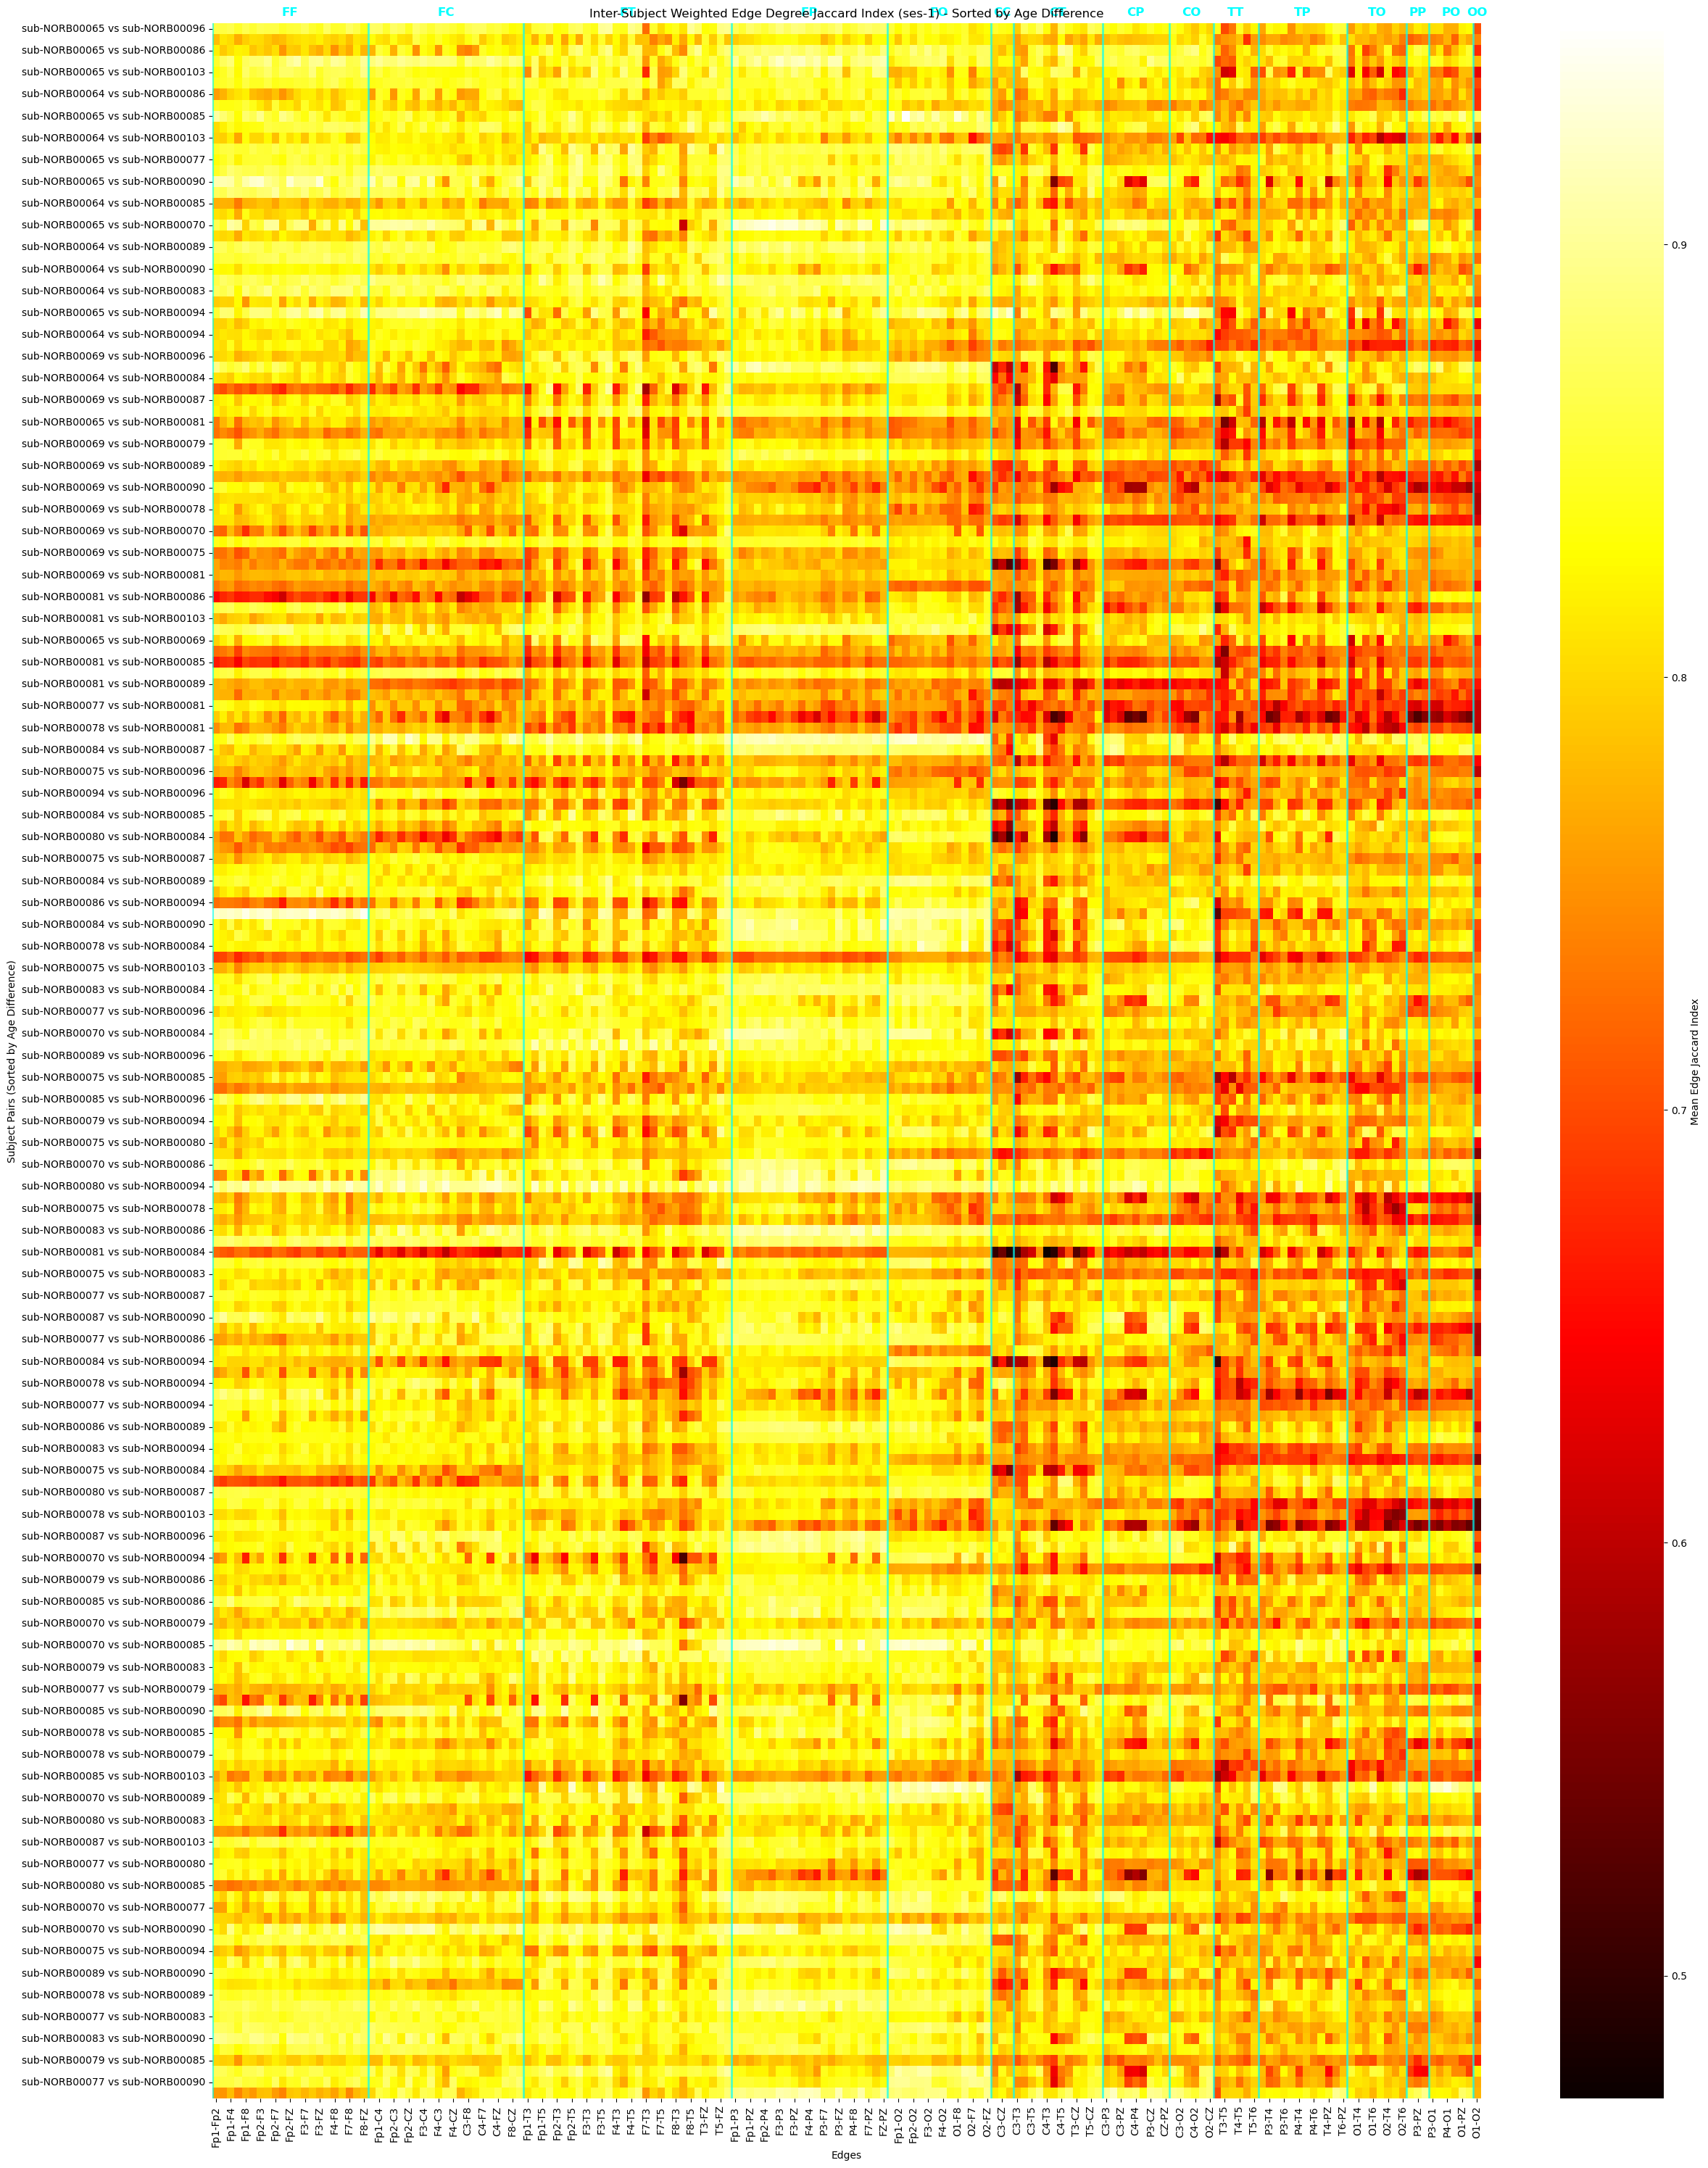

In [20]:
# 7. Plot Session 1 Inter-Subject Weighted Jaccard Heatmap sorted by Age Difference
if not jaccard_edge_df.empty:
    import itertools
    
    # Sort the subject pairs by age difference (descending, so least diff is at bottom)
    pair_ages = jaccard_edge_df[['subject_pair', 'age_diff']].drop_duplicates()
    pair_ages = pair_ages.sort_values('age_diff', ascending=False)
    sorted_pairs = pair_ages['subject_pair'].tolist()
    
    # --- Sort the edge pairs by band order ---
    band_order = 'FCTPO'
    order_keys = [a + b for i, a in enumerate(band_order) for b in band_order[i:]]
    order_map = {k: i for i, k in enumerate(order_keys)}
    
    def band_key(edge_label):
        a, b = edge_label.split('-')
        return ''.join(sorted((a[0].upper(), b[0].upper()), key=lambda c: band_order.index(c)))
        
    unique_edges = jaccard_edge_df['edge_label'].unique().tolist()
    sorted_edge_labels = sorted(unique_edges, key=lambda ep: order_map[band_key(ep)])
    
    # Pivot the dataframe for the heatmap
    heatmap_df = jaccard_edge_df.pivot(index='subject_pair', columns='edge_label', values='avg_jaccard')
    
    # Reorder rows based on sorted age difference and columns based on sorted edges
    heatmap_df = heatmap_df.reindex(index=sorted_pairs, columns=sorted_edge_labels)
    
    plt.figure(figsize=(25, 30))
    ax = sns.heatmap(heatmap_df, 
                cmap='hot', 
                cbar_kws={'label': 'Mean Edge Jaccard Index'})
    
    # --- Draw vertical lines separating the band groups ---
    col_band_keys = [band_key(ep) for ep in sorted_edge_labels]
    unique_band_keys = [k for k in order_keys if k in col_band_keys]
    
    for key in unique_band_keys:
        indices = [i for i, k in enumerate(col_band_keys) if k == key]
        if indices:
            # Add a vertical line at the start of each group
            start_idx = indices[0]
            ax.axvline(x=start_idx, color='cyan', linestyle='-', linewidth=2, alpha=0.7)
            
            # Add text label for the group right above the chart
            ax.text(start_idx + len(indices)/2, -0.5, key, 
                    ha='center', va='bottom', color='cyan', fontsize=12, fontweight='bold')
                    
    plt.title(f"Inter-Subject Weighted Edge Degree Jaccard Index ({target_session}) - Sorted by Age Difference")
    plt.xlabel("Edges")
    plt.ylabel("Subject Pairs (Sorted by Age Difference)")
    plt.tight_layout()
    plt.show()
else:
    print("No data available to plot heatmap.")